# Kanda Code — When should onion farmers sell their crop?
**Industry 4.0 (MS4001) · IIT Madras BS** · Team: Raghuram Devarayi · Parashmani Datta · Kathan Desai · Yash Arabhavi · Aaryan Choudhary

One notebook, top to bottom: **data → EDA → H1 regression → price forecasting → linear programme → backtest → sensitivity → value of IoT storage → Industry 4.0 extensions (satellite weather, value of sensor information).**
Every number in the report, the deck and the viva guide comes from the functions in `src/kandacode.py`, called here.

| Step | Course concept | Function |
|---|---|---|
| 1 Data | data cleaning, validation | `clean_maharashtra`, `build_monthly`, `validate_against_lasalgaon` |
| 2 EDA | descriptive analytics, seasonality, volatility | `eda_stats`, `seasonal_profile` |
| 3 H1 | multiple regression (log-log, dummies) | `h1_regressions` |
| 4 Forecast | moving average, exponential smoothing, Holt-Winters, regression | `forecast`, `evaluate_forecasts` |
| 5 Optimise | linear programming, shadow prices | `solve_lp` |
| 6 Validate | backtest on unseen prices | `backtest`, `paired_tests` |
| 7 Industry 4.0 | value of IoT-monitored storage | `sensitivity`, `industry40_value` |
| 8 Extensions | satellite weather (H4, OLS); value of loss-rate information (LP scenarios) | `load_power`, `weather_price_link`, `value_of_loss_information` |

In [1]:
# Reproducibility: pandas, numpy, statsmodels, scipy, matplotlib, pulp==2.9.0 (bundled CBC solver)
# !pip install -q statsmodels "pulp==2.9.0"
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT / 'src'))
import numpy as np, pandas as pd
import kandacode as kc
from IPython.display import Image, display
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
print('project root:', ROOT)

project root: D:\Industry4\KandaCode


## 1 · Data
**Main dataset:** Shelar, Hajare & Mangarule (2025), *Spatio-temporal onion price dataset 2014–2024*, Mendeley Data, DOI 10.17632/ds9jmxp9zy.1 (CC BY 4.0), an Agmarknet compilation of 965,314 daily market records.

**Data check, as the proposal planned.** The compilation has **no Lasalgaon APMC records** (0 rows). So we use the **Maharashtra arrival-weighted modal price** across all Maharashtra APMCs and validate it against **NHRDF's official Lasalgaon monthly series** (Mendeley 10.17632/9dn4g8m97m, 1996–Jun 2019).

**Cleaning rules:**
- Keep Maharashtra rows.
- Drop modal prices outside ₹50–20,000/quintal (₹0.5–200/kg), and prices outside 0.2–5× that day's cross-market median.
- Drop non-positive arrivals and exact duplicates.
- **Collapse to one row per market-day.** Agmarknet repeats a market's total arrivals on each variety row, so summing those rows would double-count about 2 million tonnes.

In [2]:
raw = kc.load_raw()
mh, clean_log = kc.clean_maharashtra(raw)
daily = kc.build_daily(mh)
monthly = kc.build_monthly(mh)
nasik = kc.build_market_monthly(mh, 'Nasik')
nh = kc.load_nhrdf()
kc.LONG_HISTORY = nh['lasalgaon_price_rs_qtl'].dropna().loc[:'2013-12']   # 1996-2013 Lasalgaon history, used only for seasonal indices
print(json.dumps(clean_log, indent=1))
monthly.head()

{
 "rows_all_india": 965314,
 "rows_maharashtra": 91898,
 "markets_maharashtra": 96,
 "lasalgaon_rows_in_main_dataset": 0,
 "dropped_price_outside_band": 42,
 "dropped_nonpositive_arrivals": 0,
 "dropped_duplicates": 0,
 "flag_min_modal_max_inconsistent": 0,
 "dropped_relative_price_outliers": 58,
 "rows_clean_records": 91798,
 "market_days_with_multiple_variety_rows": 5672,
 "multi_row_market_days_with_repeated_arrivals_pct": 100.0,
 "tonnes_double_counted_if_rows_summed": 1979857.0,
 "market_days_clean": 85346,
 "rows_clean": 85346,
 "date_min": "2014-01-01",
 "date_max": "2024-12-31"
}


,price_rs_qtl,price_median_rs_qtl,arrivals_t,market_days,markets_reporting,trading_days,arrivals_per_market_day_t,arrivals_per_market_t,year,month
ym,,,,,,,,,,
2014-01,869.726777,900.0,133663.7,288,28,31,464.110069,4773.703571,2014,1
2014-02,584.939855,600.0,138947.4,170,28,28,817.337647,4962.407143,2014,2
2014-03,663.737371,700.0,209643.7,247,32,31,848.759919,6551.365625,2014,3
2014-04,792.333419,700.0,120105.1,214,31,30,561.238785,3874.358065,2014,4
2014-05,914.377211,850.5,119644.5,220,26,30,543.838636,4601.711538,2014,5


In [3]:
val = kc.validate_against_lasalgaon(monthly, nasik, nh)
spot = kc.spotcheck_2020_2024(monthly)   # 19 independently reported Lasalgaon prices, 2020-24
print({k: v for k, v in spot.items() if k != 'rows'})
val   # levels r ≈ 0.99, monthly changes r ≈ 0.93 over 66 months

{'points': 19, 'median_abs_gap_pct': 17.7, 'median_signed_gap_pct': -10.2, 'share_ours_below_pct': 84.0, 'pearson_r': 0.9, 'msamb_points': 8, 'msamb_median_signed_gap_pct': -19.0}


{'overlap_months': 66,
 'overlap_start': '2014-01',
 'overlap_end': '2019-06',
 'pearson_r_levels': 0.9896,
 'pearson_r_logs': 0.9821,
 'pearson_r_monthly_log_changes': 0.9254,
 'mean_ratio_mh_to_lasalgaon': 0.973,
 'mean_abs_pct_gap': 8.78,
 'direction_agreement_pct': 87.7,
 'season_shape': [{'year': 2014,
   'rise_composite_pct': 128.0,
   'rise_lasalgaon_pct': 112.4},
  {'year': 2015, 'rise_composite_pct': 307.9, 'rise_lasalgaon_pct': 277.9},
  {'year': 2016, 'rise_composite_pct': 30.5, 'rise_lasalgaon_pct': 18.2},
  {'year': 2017, 'rise_composite_pct': 426.6, 'rise_lasalgaon_pct': 602.0},
  {'year': 2018, 'rise_composite_pct': 63.2, 'rise_lasalgaon_pct': 95.5}],
 'nasik_overlap_months': 53,
 'nasik_pearson_r': 0.9724,
 'composite_vs_nasik_r_2023_2024': 0.9805,
 'composite_over_nasik_ratio_2023_2024': 0.948}

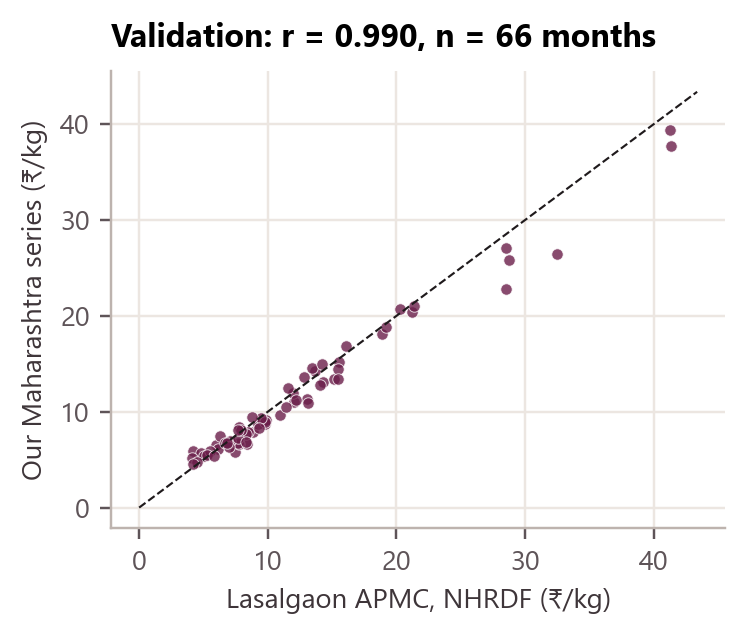

In [4]:
display(Image(str(kc.FIG / 'f8_validation.png'), width=420))

## 2 · Exploratory data analysis — seasonality and volatility

In [5]:
eda = kc.eda_stats(monthly, daily)
{k: v for k, v in eda.items() if k not in ('season_rise', 'yearly')}

{'monthly_obs': 132,
 'price_mean_rs_kg': 14.88,
 'price_min_rs_kg': 4.51,
 'price_min_month': '2019-02',
 'price_max_rs_kg': 50.56,
 'price_max_month': '2019-12',
 'overall_cv_pct': 60.9,
 'mean_within_year_cv_pct': 48.8,
 'mean_max_over_min_within_year': 4.58,
 'mom_change_sd_pct': 32.5,
 'share_months_abs_change_gt_20pct': 46.6,
 'monthly_log_return_sd_pct': 29.3,
 'annualised_vol_from_monthly_pct': 101.5,
 'mean_rise_apr_to_best_pct_hindsight': 255.9,
 'median_rise_apr_to_best_pct_hindsight': 218.3,
 'median_rise_apr_to_nov_pct': 148.3,
 'years_nov_above_apr': 11,
 'years': 11,
 'years_best_month': {'Nov': 5,
  'Oct': 2,
  'Aug': 1,
  'Jul': 1,
  'Dec': 1,
  'Sep': 1}}

In [6]:
pd.DataFrame(eda['season_rise'])   # April price vs best later month, each year

,year,apr,best_later,best_month,rise_pct,apr_to_nov_pct
0,2014,792.3,1806.9,Jul,128.0,65.5
1,2015,966.5,3942.8,Aug,307.9,117.1
2,2016,666.8,870.0,Nov,30.5,30.5
3,2017,514.7,2710.2,Nov,426.6,426.6
4,2018,671.1,1095.0,Oct,63.2,40.2
5,2019,680.5,5055.7,Dec,643.0,498.5
6,2020,999.7,3498.4,Nov,250.0,250.0
7,2021,815.2,2318.7,Oct,184.4,148.3
8,2022,796.2,1764.1,Nov,121.6,121.6
9,2023,593.5,3213.9,Nov,441.5,441.5


In [7]:
kc.seasonal_profile(monthly).round(3)

,price_index_mean,price_index_min,price_index_max,arrivals_index_mean,price_mean_rs_qtl
Jan,1.086,0.304,2.251,1.250,1494.937
Feb,0.873,0.251,1.717,1.273,1247.177
Mar,0.641,0.298,0.894,1.190,924.364
Apr,0.553,0.378,0.868,0.970,786.834
May,0.577,0.338,0.881,0.953,831.365
Jun,0.789,0.378,1.192,0.928,1151.968
Jul,0.894,0.375,1.511,0.956,1308.872
Aug,1.126,0.564,2.053,0.911,1710.846
Sep,1.205,0.764,1.962,0.845,1909.133
Oct,1.401,0.845,1.846,0.809,2141.752


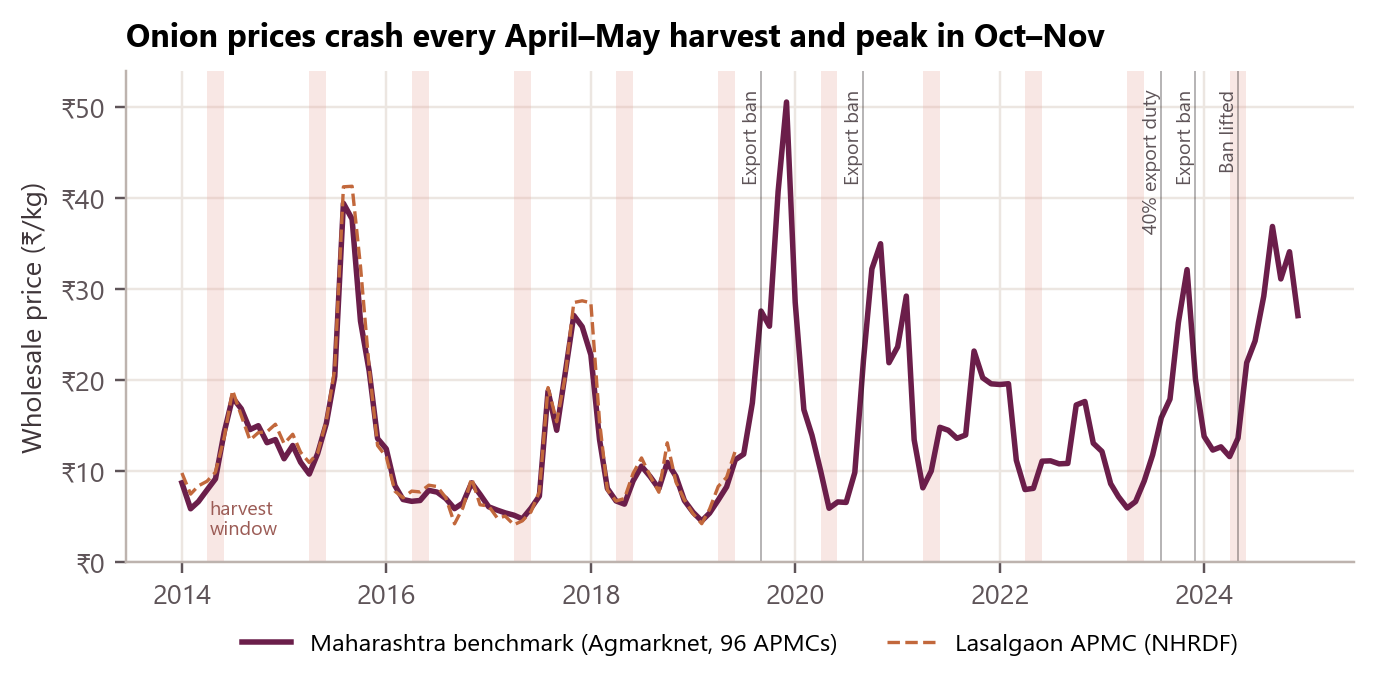

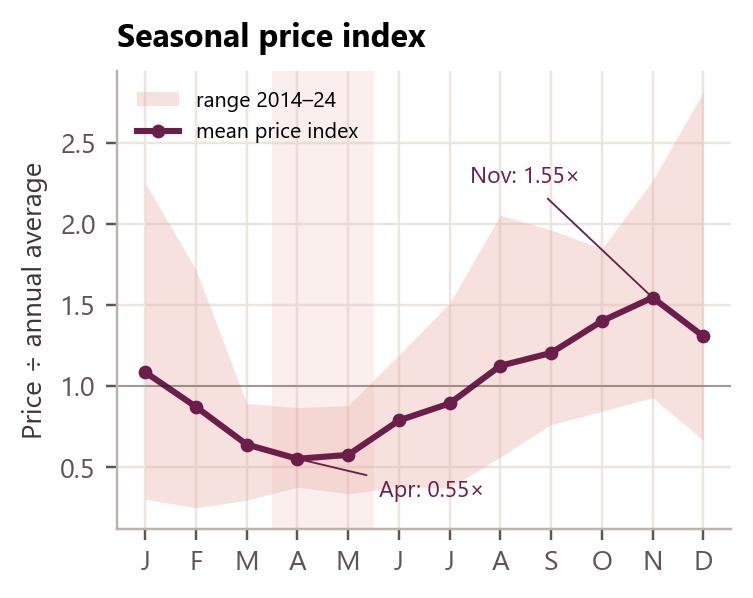

In [8]:
display(Image(str(kc.FIG / 'f1_price_history.png'))); display(Image(str(kc.FIG / 'f2_seasonality.png'), width=420))

## 3 · H1 — do arrivals drive price?
Model: $\ln P_t = \alpha + \beta \ln A_t + \text{month dummies} + \text{year dummies} + \varepsilon_t$.
β is an **elasticity**: the % change in price for a 1% change in arrivals (arrivals per reporting market-day, so changes in market coverage do not count as supply).
Standard errors: OLS and Newey–West HAC (robust to autocorrelation).

In [9]:
h1 = kc.h1_regressions(monthly, daily)
pd.DataFrame({k: v for k, v in h1.items() if k[:1] in 'MD'}).T[['n','elasticity','se_ols','p_ols','se_hac','p_hac','adj_r2','durbin_watson']]

,n,elasticity,se_ols,p_ols,se_hac,p_hac,adj_r2,durbin_watson
M1_simple,132,-0.7565,0.1694,0.000017,0.2863,0.008229,0.126,0.34
M2_month_FE,132,-0.6701,0.1738,0.000187,0.2221,0.002549,0.358,0.33
M3_month_year_FE,132,-0.442,0.1743,0.01261,0.1782,0.013143,0.529,0.52
M4_lagged_arrivals,131,-0.1338,0.1768,0.450742,0.209,0.521978,0.504,0.52
M5_dynamic_with_lagged_price,131,-0.0144,0.1097,0.895701,0.1352,0.915125,0.831,1.68
D1_daily_sign_check,3972,-0.0769,0.0122,0.0,0.0309,0.012937,0.55,0.1


In [10]:
h1['headline'], h1['robust_normalisation'], h1['reverse_causality_lnA_on_lagged_price']

({'spec': 'M3_month_year_FE',
  'elasticity': -0.442,
  'interpretation': 'Months with 10% heavier arrivals (per market-day) have prices about 4% lower, holding month-of-year and year constant. This is an association, not a causal elasticity.',
  'one_sided_p_hac': 0.0065717274061516855,
  'H1_supported': True},
 {'per_market_day (headline)': {'elasticity': -0.442,
   'p_hac': 0.013143454812303371},
  'per_market_reporting': {'elasticity': -0.2717,
   'p_hac': 0.05817453276444939},
  'total_arrivals': {'elasticity': -0.2471, 'p_hac': 0.07899010601129246},
  'per_market_day_excl_covid_AprMay2020': {'elasticity': -0.5717,
   'p_hac': 0.0005223251100616336}},
 {'elasticity': -0.1548, 'p_hac': 0.010716497323591387, 'n': 131})

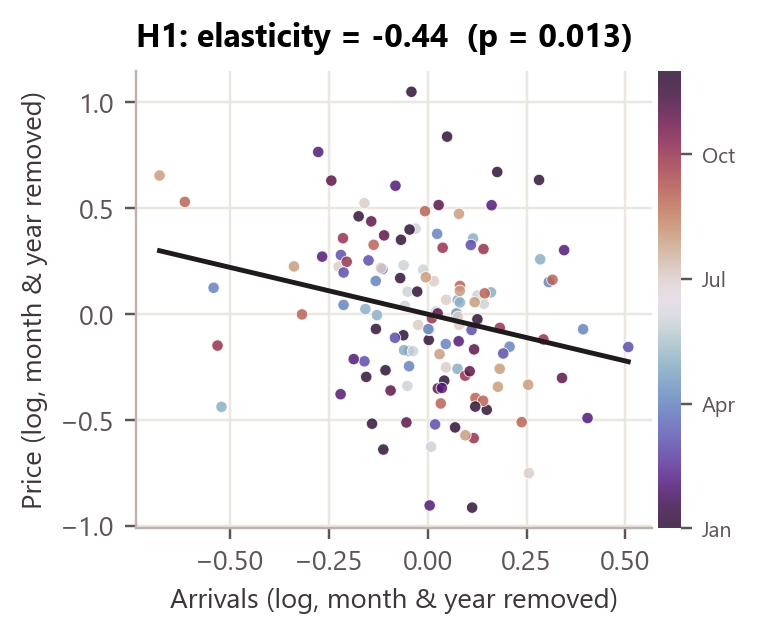

In [11]:
display(Image(str(kc.FIG / 'f3_price_arrivals.png'), width=420))

In [12]:
base = kc.LPParams()
kc.price_taker_check(monthly, base.Q, base.U, h1['headline']['elasticity'], nh)   # FPO is a price-taker (order of magnitude)

{'lasalgaon_mean_april_arrivals_t': 27752.0,
 'lasalgaon_mean_oct_nov_arrivals_t': 16800.0,
 'fpo_max_april_sale_t': 1000.0,
 'fpo_max_later_monthly_sale_t': 300.0,
 'share_april_pct': 3.6,
 'share_oct_nov_pct': 1.79,
 'implied_price_impact_april_pct': 1.59,
 'implied_price_impact_oct_nov_pct': 0.79,
 'note': "Elasticity is from the Maharashtra composite; applying it to one APMC's tonnage is an order-of-magnitude check."}

## 4 · Forecasting the price path
The decision is taken at the **end of March**, so each model forecasts **April–December (1–9 months ahead)** from that origin.
- Expanding window: only data up to the origin is used.
- **Selection:** the model with the lowest MAPE on the validation seasons 2019–2022.
- **Test:** 2023 and 2024, never used for selection.
- We also report rolling 1-month-ahead accuracy.

In [13]:
series = monthly['price_rs_qtl'].dropna()
fe = kc.evaluate_forecasts(series)
tab = (pd.DataFrame(fe['validation_horizon']).T[['MAPE']].rename(columns={'MAPE': 'VALID_2019_22_MAPE'})
       .join(pd.DataFrame(fe['decision_horizon']).T.add_prefix('TEST_'))
       .join(pd.DataFrame(fe['one_step']).T[['MAPE']].rename(columns={'MAPE': '1step_MAPE'})))
tab.index = [kc.FORECAST_LABELS[i] for i in tab.index]
tab.sort_values('VALID_2019_22_MAPE')

,VALID_2019_22_MAPE,TEST_MAPE,TEST_RMSE_rs_qtl,TEST_MAE_rs_qtl,TEST_bias_pct,TEST_direction_hit_pct,1step_MAPE
Regression: trend + month dummies,36.94,29.50,840.67,660.48,-17.11,93.75,27.08
Seasonal naive (same month last year),42.06,34.84,897.31,740.41,-25.89,87.50,39.86
Naive (last month),44.44,45.62,1387.55,1125.33,-41.37,0.00,21.68
28-yr seasonal index x moving average,47.35,29.49,906.04,728.37,-27.11,81.25,20.12
Regression: level + month effects,48.60,30.45,909.10,739.66,-29.11,87.50,21.65
Seasonal index x moving average,50.68,29.32,912.83,729.94,-28.21,93.75,20.86
Holt-Winters (damped trend + seasonality),57.36,23.85,742.66,577.51,-23.21,93.75,12.94
28-yr seasonal index x exponential smoothing,58.02,19.55,650.17,483.05,-18.17,81.25,13.66
Seasonal index x exponential smoothing,58.23,22.45,706.16,541.77,-22.20,93.75,14.04
12-month moving average,62.27,43.87,1151.94,951.34,-17.93,0.00,34.81


In [14]:
best = fe['best_method']; print('chosen model:', kc.FORECAST_LABELS[best])

chosen model: Regression: trend + month dummies


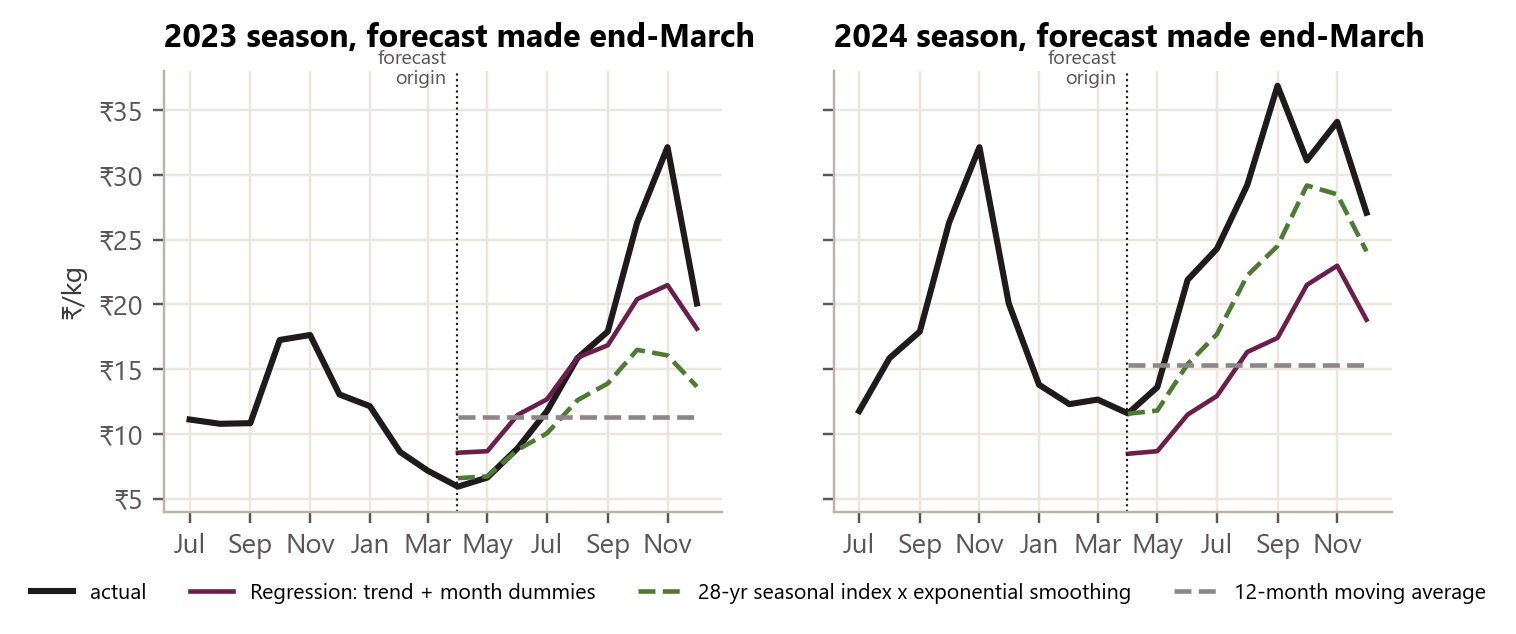

In [15]:
display(Image(str(kc.FIG / 'f4_forecast_test.png')))

## 5 · The linear programme (sell-or-store plan)
**Decision variables:** $x_t$ = tonnes sold in month $t$; $s_t$ = tonnes in storage at the end of month $t$ ($t=1$ April … $9$ December).

**Objective:** maximise $Z=\sum_t \hat p_t x_t - h\sum_t s_t$

**Constraints:**

| Constraint | Formula | Meaning |
|---|---|---|
| Harvest balance | $s_1 = Q - x_1$ | Whatever is not sold in April goes into storage |
| Stock balance | $s_t = (1-\delta)s_{t-1} - x_t$ | Last month's stock, minus rot, minus sales |
| Capacity | $s_t \le C$ | Stock never exceeds storage space |
| Loan repayment | $x_1 \ge L$ | Minimum sale at harvest |
| Handling capacity | $x_t \le U$ for $t\ge2$ | Monthly grading and trucking limit |
| Clear by December | $s_9 = 0$ | Season ends with no stock |
| Non-negativity | $x, s \ge 0$ | No negative sales or stock |

**Scenarios:**
- **A:** no storage ($C=0$).
- **B:** ventilated kanda chawl, δ = 1−(1−0.5489)^{1/4} ≈ 18.0%/month (ICAR: 54.89% loss in 120 days).
- **C:** cold / IoT-monitored storage, δ ≈ 1.83%/month (ICAR-DOGR: 7.14% in 120 days).

**Solvers:** PuLP + CBC, cross-checked with SciPy (HiGHS), which also returns shadow prices.

In [16]:
from dataclasses import asdict
print(asdict(base)); print({k: {kk: round(vv, 4) if isinstance(vv, float) else vv for kk, vv in v.items()} for k, v in kc.SCENARIOS.items()})
tr = series[series.index <= pd.Period('2024-03', 'M')]
fc = kc.forecast(tr, 9, best) * 10       # Rs/quintal -> Rs/tonne
plans = {k: kc.solve_lp(fc, kc.scenario_params(base, k)) for k in 'ABC'}
pd.DataFrame({k: np.round(v['x'], 1) for k, v in plans.items()}, index=kc.SEASON)

{'Q': 1000.0, 'C': 700.0, 'L': 250.0, 'U': 300.0, 'delta': 0.18, 'h': 250.0, 'T': 9, 'first_is_harvest': True}
{'A': {'name': 'No storage (sell all at harvest)', 'C': 0.0, 'delta': 0.0, 'h': 0.0}, 'B': {'name': 'Ventilated kanda chawl', 'delta': 0.1805, 'h': 250.0}, 'C': {'name': 'Cold / IoT-monitored storage', 'delta': 0.0183, 'h': 700.0}}


,A,B,C
Apr,1000.0,1000.0,300.0
May,0.0,0.0,0.0
Jun,0.0,0.0,0.0
Jul,0.0,0.0,0.0
Aug,0.0,0.0,0.0
Sep,0.0,0.0,21.2
Oct,0.0,0.0,300.0
Nov,0.0,0.0,300.0
Dec,0.0,0.0,0.0


In [17]:
pd.DataFrame({k: {'objective_Rs_lakh': v['objective']/1e5, 'scipy_cross_check': v['objective_match'],
                  'tonnes_lost_to_rot': v['lost_total']} for k, v in plans.items()}).T

,objective_Rs_lakh,scipy_cross_check,tonnes_lost_to_rot
A,84.735668,True,0.0
B,84.735668,True,0.0
C,132.511525,True,78.834611


In [18]:
# Shadow prices VERIFIED by re-solving with each right-hand side moved +/- 1 tonne (scenario C, 2024 forecast)
kc.marginal_values(fc, kc.scenario_params(base, 'C'))

{'applicable': True,
 'capacity_C': {'gain_if_plus_1t': 4028.4, 'loss_if_minus_1t': 4028.4},
 'loan_sale_L': {'gain_if_plus_1t': 0.0, 'loss_if_minus_1t': -0.0},
 'harvest_Q': {'gain_if_plus_1t': 8473.6, 'loss_if_minus_1t': 8473.6},
 'handling_cap_U': {'gain_if_plus_1t': 6525.6, 'loss_if_minus_1t': 6525.6},
 'degenerate_C_equals_Q_minus_L': False}

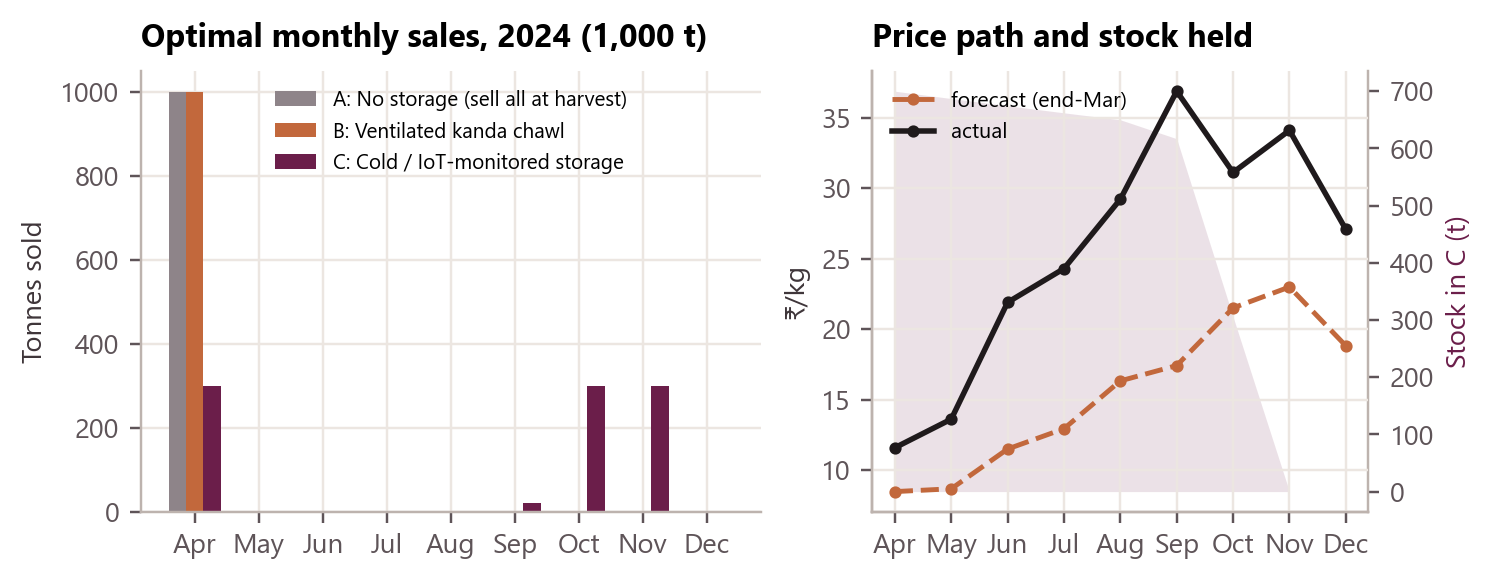

In [19]:
display(Image(str(kc.FIG / 'f5_lp_plan_2024.png')))

## 6 · Backtest on prices the model never saw (H2, H3)

In [20]:
bt = kc.backtest(series, [2023, 2024], base, best)
bt[['year','scenario','strategy','net_per_t','gain_vs_harvest_per_t','oracle_net_per_t','sold_t']].round(0)

,year,scenario,strategy,net_per_t,gain_vs_harvest_per_t,oracle_net_per_t,sold_t
0,2023,B,calendar_rule_exante,5803.0,-132.0,NaN,559.0
1,2023,B,calendar_rule_hindsight_OctNov,6687.0,752.0,NaN,512.0
2,2023,C,calendar_rule_exante,13434.0,7499.0,NaN,931.0
3,2023,C,calendar_rule_hindsight_OctNov,16670.0,10735.0,NaN,920.0
4,2023,A,forecast_plan,5935.0,0.0,5935.0,1000.0
5,2023,B,forecast_plan,5935.0,0.0,6687.0,1000.0
6,2023,B,rolling_replan,5935.0,0.0,6687.0,1000.0
7,2023,B,perfect_foresight,6687.0,752.0,6687.0,512.0
8,2023,C,forecast_plan,16668.0,10733.0,16690.0,922.0
9,2023,C,rolling_replan,16668.0,10733.0,16690.0,922.0


In [21]:
bt_rob = kc.backtest(series, list(range(2017, 2025)), base, best)
bt_rob.pivot_table(index='year', columns=['scenario','strategy'], values='gain_vs_harvest_per_t').round(0)

scenario             A                    B                                                                                                  C  \
strategy forecast_plan calendar_rule_exante calendar_rule_hindsight_OctNov forecast_plan perfect_foresight rolling_replan calendar_rule_exante   
year                                                                                                                                             
2017               0.0               -467.0                          107.0           0.0            1727.0            0.0               5172.0   
2018               0.0              -3225.0                        -3051.0           0.0               0.0            0.0              -1324.0   
2019               0.0               1764.0                           57.0           0.0            1764.0            0.0               9941.0   
2020               0.0              -1864.0                         -840.0           0.0               0.0            0.0               7803.0   
2021               0.0              -2705.0                        -1465.0           0.0             597.0            0.0               3451.0   
2022               0.0              -3381.0                        -2589.0           0.0               0.0            0.0                786.0   
2023               0.0               -132.0                          752.0           0.0             752.0            0.0               7499.0   
2024               0.0                822.0                        -2188.0           0.0            1488.0            0.0              10734.0   

scenario                                                                                
strategy calendar_rule_hindsight_OctNov forecast_plan perfect_foresight rolling_replan  
year                                                                                    
2017                             8198.0        2929.0            9030.0         2929.0  
2018                            -1507.0       -1181.0             532.0        -1181.0  
2019                            13190.0        3069.0           19439.0         3069.0  
2020                            10551.0        4865.0           10626.0         4583.0  
2021                             4663.0        4610.0            4692.0         4610.0  
2022                             2106.0        2118.0            2183.0         2118.0  
2023                            10735.0       10733.0           10755.0        10733.0  
2024                             8944.0        9226.0           11206.0         9226.0

In [22]:
kc.paired_tests(bt_rob)

{'H2_B_vs_A': {'n_seasons': 8,
  'mean_diff_rs_per_t': 0.0,
  'median_diff_rs_per_t': 0.0,
  'min_diff_rs_per_t': 0.0,
  'max_diff_rs_per_t': 0.0,
  'wins': 0,
  'ties': 8,
  'paired_t_one_sided_p': None,
  'wilcoxon_one_sided_p': None,
  'note': 'not testable: every season identical (the B plan never stores, so it equals harvest sale)'},
 'C_vs_A': {'n_seasons': 8,
  'mean_diff_rs_per_t': 4546.0,
  'median_diff_rs_per_t': 3840.0,
  'min_diff_rs_per_t': -1181.0,
  'max_diff_rs_per_t': 10733.0,
  'wins': 7,
  'ties': 0,
  'paired_t_one_sided_p': 0.0062,
  'wilcoxon_one_sided_p': 0.0078},
 'H3_C_vs_B': {'n_seasons': 8,
  'mean_diff_rs_per_t': 4546.0,
  'median_diff_rs_per_t': 3840.0,
  'min_diff_rs_per_t': -1181.0,
  'max_diff_rs_per_t': 10733.0,
  'wins': 7,
  'ties': 0,
  'paired_t_one_sided_p': 0.0062,
  'wilcoxon_one_sided_p': 0.0078}}

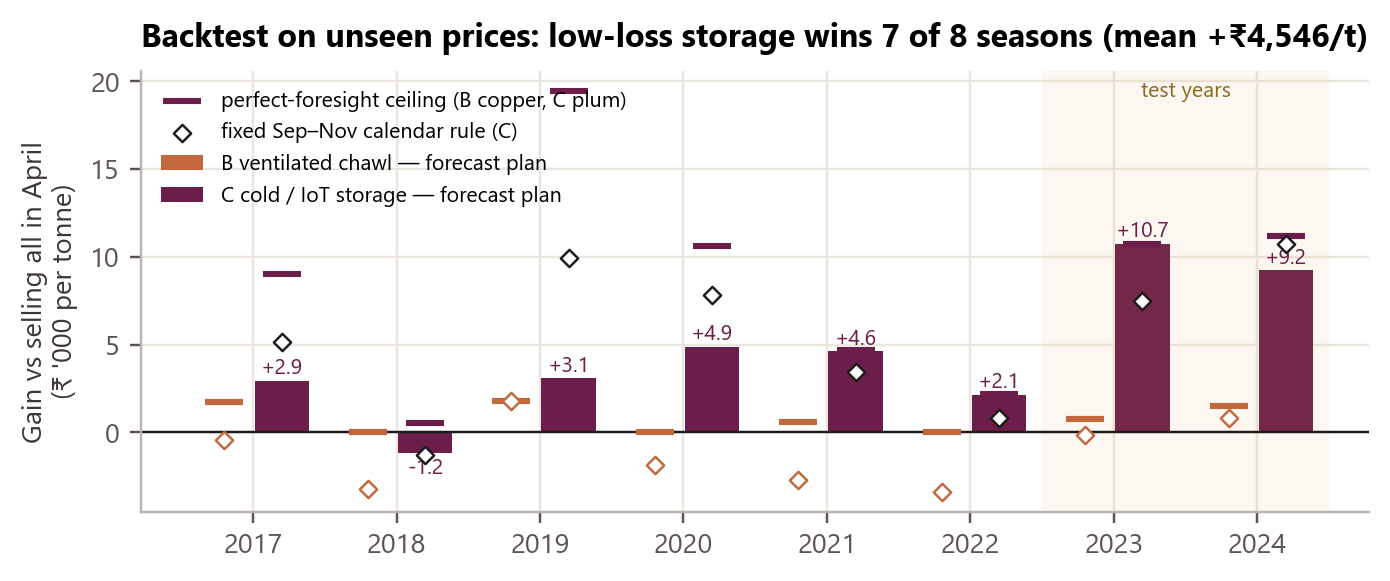

In [23]:
display(Image(str(kc.FIG / 'f6_backtest.png')))

## 7 · Sensitivity and the rupee value of IoT-monitored storage (Industry 4.0)

In [24]:
sens = kc.sensitivity(series, list(range(2017, 2025)), base, best)
pd.DataFrame(sens['grid_delta_h']).T   # rows: monthly loss δ ; cols: storage cost h ; value = avg gain Rs/t vs harvest sale

,0,250,500,750,1000
0.02,7844.0,6686.0,5234.0,4240.0,3119.0
0.06,4556.0,3172.0,2481.0,1039.0,199.0
0.10,1941.0,890.0,-43.0,-529.0,-228.0
0.14,327.0,-508.0,-219.0,0.0,0.0
0.18,-730.0,0.0,0.0,0.0,0.0
0.22,0.0,0.0,0.0,0.0,0.0


In [25]:
print('break-even monthly loss for chawl storage:', sens['breakeven_delta_B'])

break-even monthly loss for chawl storage: 0.1243


In [26]:
kc.industry40_value(bt_rob, base)

{'uplift_C_over_B_rs_per_t_harvest': 4546.0,
 'uplift_C_over_B_rs_per_kg': 4.55,
 'uplift_C_over_B_rs_per_t_capacity_per_season': 6495.0,
 'capex_B_rs_per_t_capacity': 7000.0,
 'capital_recovery_factor_10y_10pct': 0.1627,
 'base_case': {'capex_C_rs_per_t': 16667.0,
  'extra_capex_rs_per_t_capacity': 9667.0,
  'annualised_extra_capex_rs_per_t': 1573.0,
  'simple_payback_seasons': 1.49,
  'net_annual_benefit_rs_per_t_capacity': 4921.0},
 'capex_range': [{'capex_C_rs_per_t': 8000.0,
   'extra_capex_rs_per_t_capacity': 1000.0,
   'annualised_extra_capex_rs_per_t': 163.0,
   'simple_payback_seasons': 0.15,
   'net_annual_benefit_rs_per_t_capacity': 6332.0},
  {'capex_C_rs_per_t': 16667.0,
   'extra_capex_rs_per_t_capacity': 9667.0,
   'annualised_extra_capex_rs_per_t': 1573.0,
   'simple_payback_seasons': 1.49,
   'net_annual_benefit_rs_per_t_capacity': 4921.0},
  {'capex_C_rs_per_t': 50000.0,
   'extra_capex_rs_per_t_capacity': 43000.0,
   'annualised_extra_capex_rs_per_t': 6998.0,
   'sim

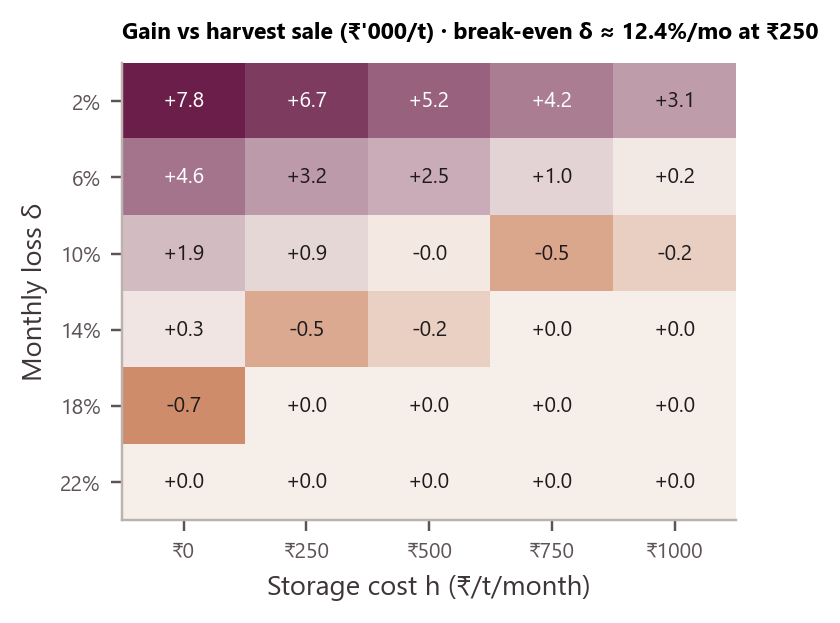

In [27]:
display(Image(str(kc.FIG / 'f7_sensitivity.png'), width=420))

## 8 · Industry 4.0 extensions: satellite weather (H4) and the value of sensor information
Added on 10 Nov 2026, **after the approved proposal**. H1–H3 above are unchanged. Two additions, both with syllabus methods only (OLS as in H1; LP scenario analysis on the same backtest):
1. **A real remote-sensing feed.** NASA POWER (NASA Langley Research Center), monthly point API, at Lasalgaon 20.15°N 74.23°E, 1996–2024: T2M (2 m air temperature, °C), RH2M (relative humidity, %), PRECTOTCORR (bias-corrected rain, mm/day, converted to mm per month). Satellite-derived and reanalysis estimates on a ~0.5° grid; free, no key. Downloaded by `src/fetch_nasa_power.py`.
2. **What sensor information is worth in rupees**: blind vs sensor vs calibrated stores.

Details: `docs/METHODOLOGY.md` §9 and `docs/EXTENSION_BRIEF.md`.

In [28]:
wx = kc.load_power()                                            # adds rain_mm = rain_mm_per_day x days in month
price_long = pd.concat([kc.LONG_HISTORY, series]).sort_index()  # NHRDF Lasalgaon 1996-2013 + our composite 2014-24
R = json.loads((kc.OUT / 'results.json').read_text(encoding='utf-8'))   # pipeline results, for checks and the slow grids
print(len(wx), 'months:', wx.index.min(), 'to', wx.index.max())
wx.head()

348 months: 1996-01 to 2024-12


,t2m_c,rh2m_pct,rain_mm_per_day,rain_mm
ym,,,,
1996-01,22.25,37.84,0.08,2.48
1996-02,24.09,29.57,0.21,6.09
1996-03,28.30,25.92,0.00,0.00
1996-04,29.77,29.32,0.04,1.20
1996-05,30.66,41.90,0.03,0.93


In [29]:
# Climate at Lasalgaon, 2014-24: RH is 82-85% in Jul-Sep, exactly when rabi onion sits in a chawl
w14 = wx[wx.index >= pd.Period('2014-01', 'M')]
clim = w14.groupby(w14.index.month)[['t2m_c', 'rh2m_pct', 'rain_mm']].mean()
clim.index = kc.MONTHS
clim.round({'t2m_c': 1, 'rh2m_pct': 1, 'rain_mm': 0})

,t2m_c,rh2m_pct,rain_mm
Jan,20.4,44.9,3.0
Feb,23.6,31.7,2.0
Mar,27.2,30.7,13.0
Apr,30.8,29.4,6.0
May,31.4,42.5,17.0
Jun,28.2,67.7,132.0
Jul,25.4,82.4,258.0
Aug,24.7,84.4,196.0
Sep,24.5,85.0,199.0
Oct,23.9,74.7,67.0


### 8.1 · H4 — does late-monsoon rain raise the post-harvest price rise?
One season = one observation (n = 29, 1996–2024). Outcome: $r_y = \ln(\overline{P}_{Oct-Dec} / P_{Apr})$. Regressor: Sep + Oct rain (mm). OLS $r_y = a + b R_y$, with HC1 robust p, Spearman ρ, wet vs dry thirds, a leave-one-season-out refit, two subperiods, and a placebo using the whole Jun–Sep monsoon.
Mechanism: late rain damages the kharif crop in the field and raises rot in stored rabi onion.

In [30]:
h4 = kc.weather_price_link(price_long, wx)
tab4 = pd.DataFrame(h4['table']).set_index('year')
tab4[['rain_sep_oct_mm', 'rain_jun_sep_mm', 'rh_sep_oct_pct', 'rise_pct', 'rise_log', 'source']]

,rain_sep_oct_mm,rain_jun_sep_mm,rh_sep_oct_pct,rise_pct,rise_log,source
year,,,,,,
1996,230.0,611.2,81.4,64.436,0.497,NHRDF Lasalgaon
1997,128.7,584.1,75.5,192.679,1.074,NHRDF Lasalgaon
1998,288.3,784.9,86.2,596.382,1.941,NHRDF Lasalgaon
1999,239.6,496.1,78.0,26.257,0.233,NHRDF Lasalgaon
2000,73.7,548.6,68.1,144.182,0.893,NHRDF Lasalgaon
2001,191.9,520.4,76.9,116.096,0.771,NHRDF Lasalgaon
2002,90.4,551.7,68.8,127.872,0.824,NHRDF Lasalgaon
2003,103.6,643.9,76.6,118.339,0.781,NHRDF Lasalgaon
2004,238.7,713.1,79.9,35.466,0.304,NHRDF Lasalgaon


In [31]:
coef = {k: h4[k] for k in ('n_seasons', 'years', 'beta_per_100mm_log', 'rise_multiplier_per_100mm', 'p_ols', 'p_robust_HC1',
                           'r2', 'ci95_ols_per_100mm', 'spearman_rho', 'spearman_p', 'mean_rain_sep_oct_mm')}
print(json.dumps(coef, indent=1))
print('wet third:', h4['wet_third'], '| dry third:', h4['dry_third'])
print('placebo (Jun-Sep monsoon):', h4['placebo_jun_sep_monsoon'])
print('leave-one-out:', h4['leave_one_out'])
print('subperiods:', h4['subperiods'])
same = all(h4[k] == R['weather']['h4_rain_price_link'][k] for k in ('beta_per_100mm_log', 'p_ols', 'p_robust_HC1', 'r2', 'n_seasons'))
print('matches outputs/results.json:', same)

{
 "n_seasons": 29,
 "years": "1996-2024",
 "beta_per_100mm_log": 0.181,
 "rise_multiplier_per_100mm": 1.198,
 "p_ols": 0.0361,
 "p_robust_HC1": 0.0025,
 "r2": 0.153,
 "ci95_ols_per_100mm": [
  0.013,
  0.349
 ],
 "spearman_rho": 0.46,
 "spearman_p": 0.012,
 "mean_rain_sep_oct_mm": 237.0
}
wet third: {'mean_rain_mm': 338.0, 'median_rise_pct': 208.0, 'n': 10} | dry third: {'mean_rain_mm': 137.0, 'median_rise_pct': 123.0, 'n': 10}
placebo (Jun-Sep monsoon): {'beta_per_100mm_log': 0.073, 'p': 0.1117, 'r2': 0.091}
leave-one-out: {'beta_min': 0.145, 'beta_max': 0.206, 'p_max': 0.0952, 'p_max_when_dropping': 2019, 'seasons_whose_removal_lifts_p_above_0_05': [2005, 2018, 2019]}
subperiods: {'1996_2013': {'n': 18, 'beta_per_100mm_log': 0.134, 'p': 0.2143}, '2014_2024': {'n': 11, 'beta_per_100mm_log': 0.273, 'p': 0.1112}}
matches outputs/results.json: True


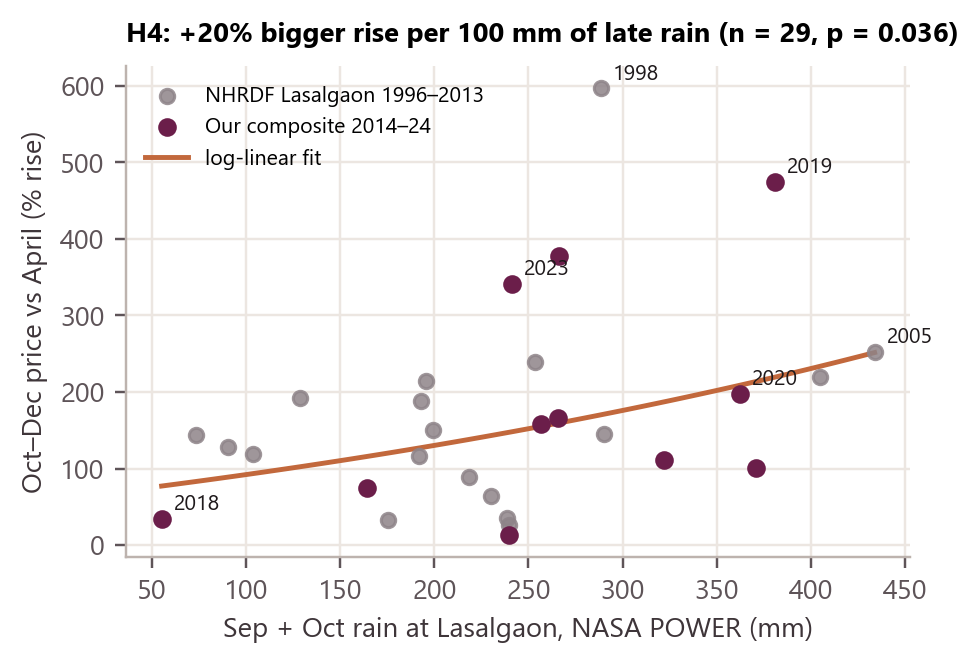

In [32]:
display(Image(str(kc.FIG / 'f10_rain_price.png'), width=460))

**Verdict: weakly supported, suggestive.** About +20% bigger rise per 100 mm (p = 0.0361, robust p = 0.0025, R² = 0.153), and the wettest third of seasons rose much more than the driest third. But dropping any one of 2005, 2018 or 2019 takes p above 0.05, neither subperiod is significant alone (same sign in both), and it is an association, not causation.

### 8.2 · Real-time use of the rain feed (1 November re-plan)
On 1 November the Sep+Oct rain is known. Nov–Dec is re-planned from the actual stock with (a) a price-only re-forecast and (b) the same forecast scaled by the H4 rain effect, with β estimated **only on earlier seasons** (no look-ahead). Read from `results.json` (`weather_replan_backtest`, run by `run_all.py`).

In [33]:
rt = R['weather']['realtime_replan_nov_dec']
print({k: {kk: vv for kk, vv in v.items() if kk != 'by_season'} for k, v in rt.items()})
pd.DataFrame(rt['C']['by_season']).set_index('year')[['rain_sep_oct_mm', 'rain_multiplier', 'stock_entering_nov_t',
                                                       'price_only', 'price_plus_rain', 'price_plus_rain_nov_dec_sales']]

{'B': {'mean_price_only': 0.0, 'mean_price_plus_rain': 0.0, 'mean_value_of_rain_feed': 0.0, 'seasons_rain_helps': 0, 'seasons_rain_hurts': 0}, 'C': {'mean_price_only': 4546.0, 'mean_price_plus_rain': 4546.0, 'mean_value_of_rain_feed': 0.0, 'seasons_rain_helps': 0, 'seasons_rain_hurts': 0}}


,rain_sep_oct_mm,rain_multiplier,stock_entering_nov_t,price_only,price_plus_rain,price_plus_rain_nov_dec_sales
year,,,,,,
2017,266.3,1.053,0.0,2929.3,2929.3,"[0.0, 0.0]"
2018,55.2,0.796,0.0,-1180.9,-1180.9,"[0.0, 0.0]"
2019,380.9,1.303,0.0,3069.1,3069.1,"[0.0, 0.0]"
2020,362.3,1.332,300.0,4864.5,4864.5,"[300.0, 0.0]"
2021,256.7,1.057,300.0,4610.1,4610.1,"[300.0, 0.0]"
2022,370.9,1.330,300.0,2118.0,2118.0,"[300.0, 0.0]"
2023,241.0,1.009,300.0,10733.4,10733.4,"[300.0, 0.0]"
2024,265.6,1.055,300.0,9226.4,9226.4,"[300.0, 0.0]"


**Value of the rain feed: ₹0/t** for both B and C. The cold-store plan enters November with at most U = 300 t, so the handling cap sends all of it to market in November in both arms; the chawl plan holds nothing. Handling capacity, not information, is the binding constraint (the U shadow price in 2024 is +₹6,526 per tonne of monthly capacity).

### 8.3 · Value of loss-rate information (the sensor / digital-twin question)
Same April forecast; the store's **true** monthly loss δ varies over a grid. Three operators:
- **blind**: plans with the book δ (B 18.05%, C 1.83%) and never learns (`solve_lp` then `_execute_plan`);
- **sensor**: measures δ from May (weighing / IoT logs) and re-plans monthly on the April forecast (`_sensor_replan`);
- **calibrated**: δ known before April from an earlier logged season (`solve_lp` with the true δ, then `_execute_plan`).

Execution enforces the real stock and the handling cap U. Gain = Rs/t vs harvest sale, mean 2017–24, with our forecast and with perfect price foresight (which isolates the pure value of loss information). The grids take a few minutes to solve, so they are read from `results.json` (`value_of_loss_information`); the cell after the tables re-solves one season to show the functions.

In [34]:
voi = R['value_of_loss_information']
cols = ['delta_true', 'blind', 'sensor', 'calibrated', 'voi_sensor', 'voi_calibrated', 'sensor_beats_blind_seasons', 'sensor_worse_seasons']
for src in ('with_forecast_prices', 'with_perfect_price_foresight'):
    for k in ('B', 'C'):
        g = pd.DataFrame(voi[src][k]['grid'])[cols]
        print(f"{src} | scenario {k} | book delta {voi[src][k]['book_delta']}")
        display(g.set_index('delta_true'))

with_forecast_prices | scenario B | book delta 0.1805


,blind,sensor,calibrated,voi_sensor,voi_calibrated,sensor_beats_blind_seasons,sensor_worse_seasons
delta_true,,,,,,,
0.0400,0.0,0.0,4691.0,0.0,4691.0,0,0
0.0600,0.0,0.0,3172.0,0.0,3172.0,0,0
0.0800,0.0,0.0,2200.0,0.0,2200.0,0,0
0.1000,0.0,0.0,890.0,0.0,890.0,0,0
0.1200,0.0,0.0,191.0,0.0,191.0,0,0
0.1400,0.0,0.0,-508.0,0.0,-508.0,0,0
0.1805,0.0,0.0,0.0,0.0,0.0,0,0
0.2200,0.0,0.0,0.0,0.0,0.0,0,0


with_forecast_prices | scenario C | book delta 0.0183


,blind,sensor,calibrated,voi_sensor,voi_calibrated,sensor_beats_blind_seasons,sensor_worse_seasons
delta_true,,,,,,,
0.0050,5404.0,5514.0,5514.0,110.0,110.0,5,3
0.0183,4549.0,4549.0,4549.0,0.0,0.0,3,3
0.0300,3712.0,3444.0,3444.0,-268.0,-268.0,5,3
0.0500,2435.0,2389.0,2389.0,-46.0,-46.0,5,3
0.0800,828.0,407.0,374.0,-421.0,-454.0,4,4
0.1000,-64.0,-621.0,-791.0,-557.0,-727.0,4,4
0.1200,-829.0,-841.0,-616.0,-13.0,213.0,4,4
0.1500,-1849.0,-1234.0,0.0,615.0,1849.0,5,3


with_perfect_price_foresight | scenario B | book delta 0.1805


,blind,sensor,calibrated,voi_sensor,voi_calibrated,sensor_beats_blind_seasons,sensor_worse_seasons
delta_true,,,,,,,
0.0400,4701.0,6471.0,8374.0,1770.0,3674.0,5,0
0.0600,3788.0,5323.0,6738.0,1535.0,2949.0,5,0
0.0800,3008.0,4300.0,5306.0,1292.0,2298.0,5,0
0.1000,2362.0,3380.0,4030.0,1017.0,1667.0,5,0
0.1200,1834.0,2571.0,2958.0,737.0,1124.0,5,0
0.1400,1406.0,1868.0,2054.0,462.0,648.0,5,0
0.1805,790.0,790.0,790.0,0.0,0.0,0,0
0.2200,106.0,144.0,231.0,38.0,125.0,2,0


with_perfect_price_foresight | scenario C | book delta 0.0183


,blind,sensor,calibrated,voi_sensor,voi_calibrated,sensor_beats_blind_seasons,sensor_worse_seasons
delta_true,,,,,,,
0.0050,9110.0,9624.0,9624.0,514.0,515.0,8,0
0.0183,8560.0,8562.0,8562.0,2.0,2.0,5,0
0.0300,7384.0,7551.0,7551.0,167.0,167.0,8,0
0.0500,5593.0,5964.0,5965.0,371.0,372.0,8,0
0.0800,3377.0,3922.0,4000.0,545.0,623.0,8,0
0.1000,2173.0,2782.0,2921.0,609.0,748.0,7,0
0.1200,1155.0,1785.0,1977.0,631.0,823.0,7,0
0.1500,-194.0,552.0,893.0,746.0,1087.0,8,0


In [35]:
# One season re-solved live (2024, cold store C, true loss 8%/month, our April forecast) to show the three operators
q = kc.scenario_params(base, 'C'); act = kc.season_prices(series, 2024)
fc24 = kc.forecast(series[series.index <= pd.Period('2024-03', 'M')], 9, best) * 10
harvest = base.Q * act[0]
blind_plan = kc.solve_lp(fc24, q, return_duals=False)
_, _, e_blind = kc._execute_plan(blind_plan['x'], q, 0.08, act)
xs_sensor, _, e_sensor = kc._sensor_replan(fc24, q, 0.08, act)
cal_plan = kc.solve_lp(fc24, kc.LPParams(**{**asdict(q), 'delta': 0.08}), return_duals=False)
_, _, e_cal = kc._execute_plan(cal_plan['x'], q, 0.08, act)
live = pd.DataFrame({'blind': e_blind, 'sensor': e_sensor, 'calibrated': e_cal}).T
live['gain_vs_harvest_per_t'] = (live['net'] - harvest) / base.Q
# (results.json keeps only the 2017-24 means per grid point at full precision; by_season rounds delta_true to 1 decimal)
live.round(0)

,revenue,storage_cost,net,gain_vs_harvest_per_t
blind,16883889.0,2469743.0,14414146.0,2827.0
sensor,17105378.0,2213464.0,14891914.0,3305.0
calibrated,17105378.0,2213464.0,14891914.0,3305.0


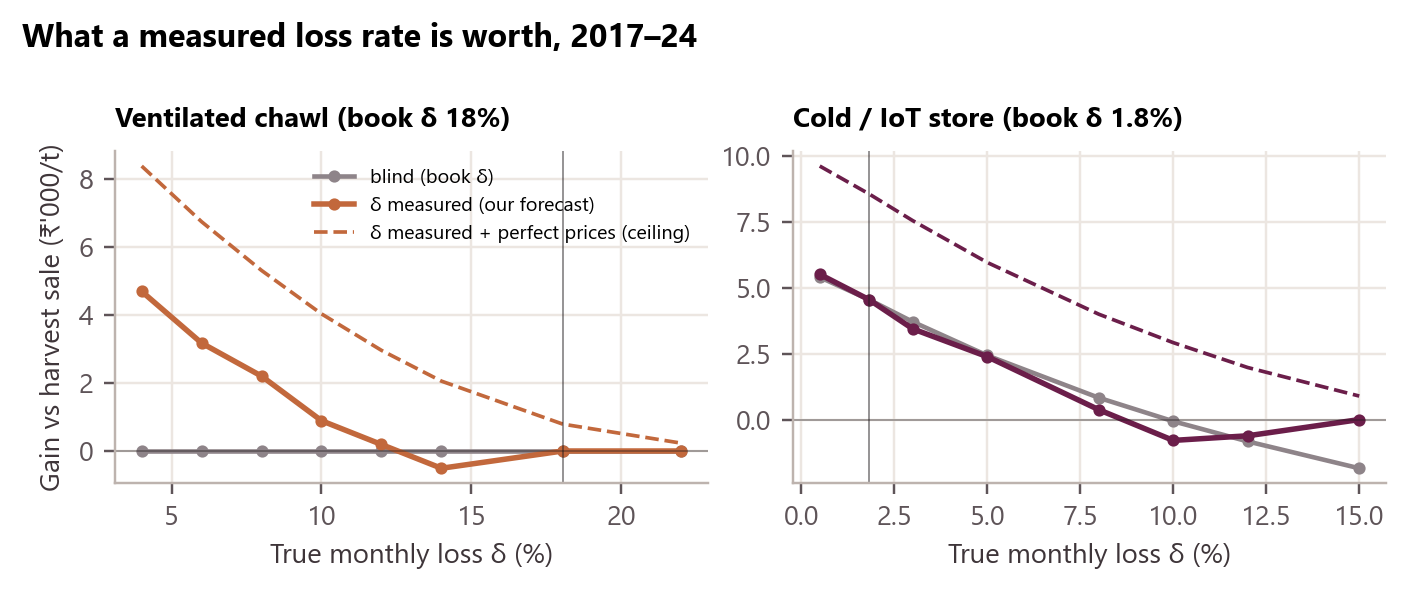

In [36]:
display(Image(str(kc.FIG / 'f11_value_of_information.png')))

**Reading.**
- **Chawl:** with the book 18% the plan sells everything in April, so in-season sensing never starts (sensor = blind = 0). A chawl *measured* at 8%/month before the season earns ₹2,200/t with our forecast; above the 12.4% break-even storing loses money (14% → −₹508/t).
- **Cold store:** with our low-biased forecast (test bias −17.11%) sensing is mixed. With accurate prices sensing is never worse and is worth ₹545–746/t when the store degrades to 8–15%/month.
- **Lesson:** sensors pay only together with a good price forecast; their biggest use is calibrating the store's real loss rate before the season. A digital twin is the forecast + LP + measured δ.

## 9 · Conclusions
- **H1 supported (as an association).** Months with heavier arrivals have lower prices: β ≈ −0.44 with month and year effects, p ≈ 0.01. It weakens with other arrival measures, and it disappears once last month's price is controlled for.
- **H2 not supported at ICAR's ventilated-storage loss.** At ≈18%/month the optimiser never stores, so the B plan equals harvest sale. A fixed calendar rule in a chawl loses money. Storage pays only below the break-even δ ≈ 12%/month.
- **H3 supported.** Low-loss (cold / IoT-monitored) storage beats harvest sale in 7 of 8 seasons: mean +₹4,546/t, Wilcoxon p = 0.008. Its extra capital cost pays back in about 1.5 seasons in the base case.
- **H4 (extension) weakly supported.** Heavier Sep+Oct rain (NASA POWER) goes with a bigger post-harvest price rise, but the link is fragile under leave-one-out. The real-time rain feed is worth ₹0/t because the handling cap binds; measuring the store's real loss rate is worth most before the season and with a good price forecast.

Limitations (quality grading, credit, price impact, forecast bias, H4 fragility) are listed in the report.